# 2. Logistic regression and a neural network from scratch: breast cancer diagnosis

**Question:** given 30 measurements of cell nuclei from a fine needle aspirate (FNA) of a breast mass, can a model tell malignant from benign?

**Data:** the [Wisconsin Diagnostic Breast Cancer dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset): 569 samples, 30 features.

**Approach:** implement logistic regression and a one-hidden-layer neural network with backpropagation in NumPy (`mlscratch/classifiers.py`), and evaluate them the way a clinician would care about, not just by accuracy.

In [1]:
import sys; sys.path.append('..')
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from mlscratch.linear_regression import StandardScaler
from mlscratch.classifiers import LogisticRegressionGD, NeuralNetwork, classification_report
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
NAVY = '#1F3864'

## Load the data and set the positive class
In the raw dataset `1` means *benign*. In medicine the condition we're screening for is the positive class, so the labels are flipped to make **1 = malignant**. That way *recall* means the share of cancers the model catches (sensitivity), which is the number that matters most.

In [2]:
data = load_breast_cancer()
X, y = data.data, 1 - data.target   # 1 = malignant
print(f'{len(y)} samples, {y.sum()} malignant ({y.mean():.0%})')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

569 samples, 212 malignant (37%)


`stratify=y` keeps the same malignant/benign ratio in the training and test sets, so the test score isn't skewed by an unlucky split.

## Train both models

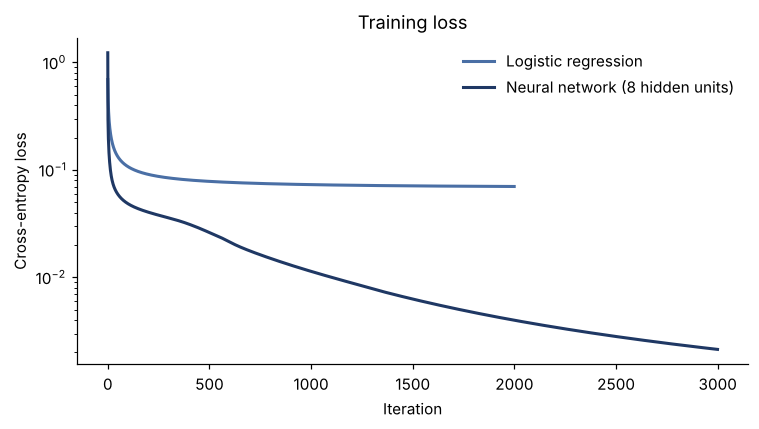

In [3]:
logreg = LogisticRegressionGD(learning_rate=0.1, iterations=2000, l2=1.0).fit(X_train_s, y_train)
nn = NeuralNetwork(hidden_units=8, learning_rate=0.5, iterations=3000).fit(X_train_s, y_train)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(logreg.loss_history_, label='Logistic regression', color='#4A6FA5', linewidth=2)
ax.plot(nn.loss_history_, label='Neural network (8 hidden units)', color=NAVY, linewidth=2)
ax.set_xlabel('Iteration'); ax.set_ylabel('Cross-entropy loss'); ax.set_yscale('log')
ax.set_title('Training loss'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('../images/classifier_loss.png', bbox_inches='tight'); plt.show()

## Evaluate on the held-out test set

In [4]:
sk = LogisticRegression(max_iter=5000).fit(X_train_s, y_train)
rows = [('Logistic regression (scratch)', logreg.predict(X_test_s)),
        ('Neural network (scratch)', nn.predict(X_test_s)),
        ('Logistic regression (scikit-learn)', sk.predict(X_test_s))]
print(f"{'Model':36}{'Accuracy':>10}{'Precision':>11}{'Recall':>8}{'F1':>7}")
for name, pred in rows:
    r = classification_report(y_test, pred)
    print(f"{name:36}{r['accuracy']:>10.3f}{r['precision']:>11.3f}{r['recall']:>8.3f}{r['f1']:>7.3f}")

Model                                 Accuracy  Precision  Recall     F1
Logistic regression (scratch)            0.982      1.000   0.952  0.976
Neural network (scratch)                 0.974      0.976   0.952  0.964
Logistic regression (scikit-learn)       0.965      0.975   0.929  0.951


## Confusion matrix
The two error types are not equal. A **false negative** (a cancer called benign) can delay treatment; a **false positive** leads to an extra biopsy.

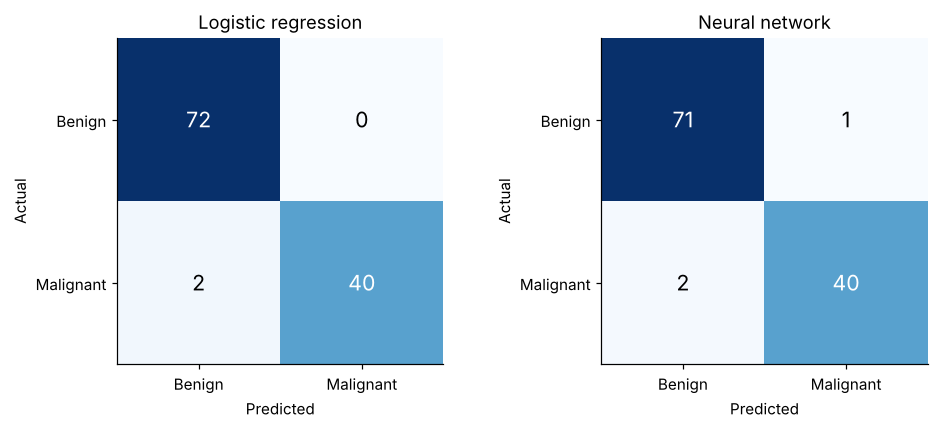

In [5]:
def plot_confusion(ax, report, title):
    c = report['confusion']
    grid = np.array([[c['tn'], c['fp']], [c['fn'], c['tp']]])
    ax.imshow(grid, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, grid[i, j], ha='center', va='center', fontsize=14,
                    color='white' if grid[i, j] > grid.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['Benign', 'Malignant']); ax.set_yticks([0, 1], ['Benign', 'Malignant'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_confusion(axes[0], classification_report(y_test, logreg.predict(X_test_s)), 'Logistic regression')
plot_confusion(axes[1], classification_report(y_test, nn.predict(X_test_s)), 'Neural network')
plt.tight_layout(); plt.savefig('../images/confusion_matrices.png', bbox_inches='tight'); plt.show()

## Trading precision for recall
The default rule is "malignant if probability ≥ 0.5". In screening, catching more cancers can be worth a few extra false alarms, so we can lower the threshold and watch the trade-off.

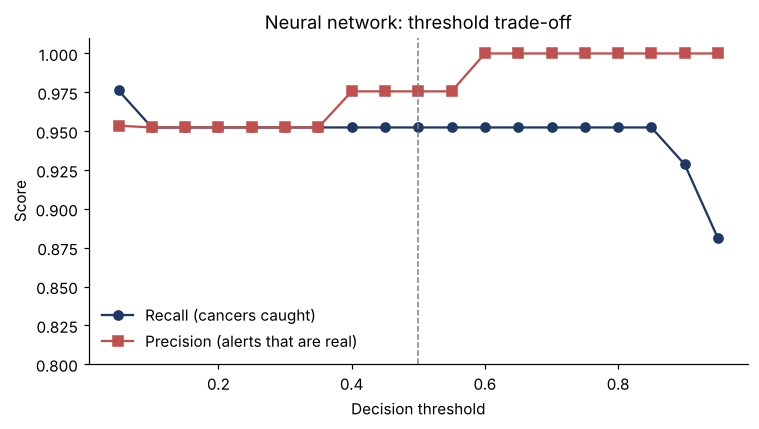

threshold 0.5: recall 0.952, precision 0.976, missed cancers 2
threshold 0.1: recall 0.952, precision 0.952, missed cancers 2
threshold 0.05: recall 0.976, precision 0.953, missed cancers 1


In [6]:
thresholds = np.linspace(0.05, 0.95, 19)
probs = nn.predict_proba(X_test_s)
recalls, precisions = [], []
for t in thresholds:
    r = classification_report(y_test, (probs >= t).astype(int))
    recalls.append(r['recall']); precisions.append(r['precision'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, recalls, 'o-', color=NAVY, label='Recall (cancers caught)')
ax.plot(thresholds, precisions, 's-', color='#C0504D', label='Precision (alerts that are real)')
ax.axvline(0.5, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('Decision threshold'); ax.set_ylabel('Score'); ax.set_ylim(0.8, 1.01)
ax.set_title('Neural network: threshold trade-off'); ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.savefig('../images/threshold_tradeoff.png', bbox_inches='tight'); plt.show()
for t in (0.5, 0.1, 0.05):
    r = classification_report(y_test, (probs >= t).astype(int))
    print(f"threshold {t}: recall {r['recall']:.3f}, precision {r['precision']:.3f}, missed cancers {r['confusion']['fn']}")

## Findings

- Both from-scratch models score between **96.5% and 98.2% test accuracy**, level with scikit-learn's logistic regression, which confirms the gradient and backpropagation code is correct. (The small edge for the from-scratch logistic regression comes from its different regularisation strength and amounts to one test sample.)
- On this dataset the neural network doesn't beat logistic regression: the classes are already close to linearly separable once features are scaled, so the extra flexibility isn't needed. The simpler, more interpretable model is the better choice here.
- **Accuracy alone is misleading for diagnosis.** The confusion matrix and the threshold curve show the real decision: at the default 0.5 threshold the network misses 2 of 42 cancers. Lowering the threshold all the way to 0.1 still misses the same 2, which means the model is *confidently* wrong about them; only at 0.05 is one caught, at the cost of an extra false alarm. Cases like these are worth handing to a pathologist to see what makes them look benign. Where that line sits is a clinical decision, not a modelling one.
- With 114 test samples, one misclassification moves accuracy by almost a percentage point. Cross-validation would give a more stable estimate.